# Nhận diện & phân loại bệnh cây trồng từ ảnh lá bằng Deep Learning
### + Đánh giá khả năng tổng quát hóa trên nhiều bộ dữ liệu

**Thiết kế thí nghiệm (tóm tắt)**

| Dataset | Vai trò | Lý do |
|---|---|---|
| **PlantVillage** (~54k ảnh, 38 lớp, nền đơn giản) | Huấn luyện nguồn + test *trong miền* | Nhiều ảnh, nhãn sạch |
| **PlantWild v1** (18.5k ảnh, 89 lớp, ảnh ngoài đồng) | Fine-tune (train) + test *ngoài miền* (test) | Đủ lớn để fine-tune, có split chính thức |
| **PlantDoc** (~2.6k ảnh, 27 lớp, ảnh ngoài đồng) | **Test độc lập, KHÔNG bao giờ train** | Nhỏ -> chỉ hợp làm bộ kiểm tra cuối |

**Hai giai đoạn:** `S1` train trên PlantVillage -> đo *zero-shot* trên ảnh thực tế (thấy rõ khoảng cách miền)
-> `S2` fine-tune trên PlantWild-train -> đo lại trên PlantWild-test và PlantDoc (chưa từng thấy).

**Mục lục:** 1 Cài đặt · 2 Cấu hình · 3 Tải dữ liệu · 4 Chỉ mục & không gian nhãn · 5 Quyết định dataset ·
6 Khám phá dữ liệu · 7 Tập đánh giá & loader · 8 Giai đoạn 1 · 9 Giai đoạn 2 · 10 Kết quả tổng hợp ·
11 Ablation augmentation · 12 Confusion matrix · 13 Grad-CAM · 14 Lưu kết quả

## Mục 1. Cài đặt môi trường

In [3]:
# # --- Cell 1.1: cài thư viện còn thiếu (torch/torchvision cài riêng trước). %pip cài đúng vào kernel đang chạy ---
# %pip install -q timm tqdm scikit-learn pandas matplotlib pillow

In [2]:
# --- Cell 1.2: trỏ Python tới thư mục dự án và import ---
import os, sys, warnings
from pathlib import Path
warnings.filterwarnings("ignore")

ROOT = Path.cwd()
if not (ROOT / "src").exists():          # notebook nằm trong notebooks/ -> lên 1 cấp
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT)); os.chdir(ROOT)

import numpy as np, pandas as pd, torch
import matplotlib.pyplot as plt
from IPython.display import display

from src.config import Config
from src.label_space import add_keys, build_label_space, attach_labels, mapping_report
from src.data_index import scan_folder, find_plantvillage_root, ensure_splits, summarize_splits, has_images
from src.analysis import coverage_report, find_near_duplicates
from src.data_loading import build_transforms, make_loader
from src.models import create_model, count_params, get_gradcam_layer
from src.train import fit, seed_everything, get_device
from src.evaluate import (evaluate_set, results_table, add_generalization_gap,
                          per_class_report, plot_confusion)
from src.gradcam import show_gradcam_grid

device = get_device()
print("Thiết bị:", device, "|", torch.cuda.get_device_name(0) if device.type == "cuda" else "CPU (rất chậm, nên bật GPU)")

Thiết bị: cuda | NVIDIA GeForce RTX 4050 Laptop GPU


## Mục 2. Cấu hình thí nghiệm
Mọi tham số nằm trong `src/config.py`. Đổi ở đây nếu cần (ví dụ máy yếu -> giảm `epochs_pv`, bỏ bớt mô hình).

In [4]:
# --- Cell 2.1: tạo cấu hình ---
cfg = Config(
    data_root="data",
    output_dir="outputs",
    use_plantdoc=True,            # False nếu không dùng PlantDoc
    use_plantwild=True,           # False -> phương án tối thiểu (xem README)
    finetune_on="plantwild",      # "plantwild" | "plantdoc" | "none"
    models=("resnet50", "efficientnet_b0", "mobilenetv3_large_100"),
    epochs_pv=6, epochs_ft=8,
    batch_size=64, num_workers=2,
    augmentation="strong",
    # manual_label_overrides={"tên lớp gốc": "crop__condition"},   # sửa ánh xạ sai ở Mục 4
)
seed_everything(cfg.seed)
print(cfg)

Config(data_root=WindowsPath('data'), output_dir=WindowsPath('outputs'), pv_override='', pd_override='', pw_override='', use_plantdoc=True, use_plantwild=True, finetune_on='plantwild', plantdoc_eval_on_all=True, pw_exclude=('v2',), pv_val_frac=0.15, pv_test_frac=0.15, pw_val_frac=0.1, pw_test_frac=0.2, seed=42, models=('resnet50', 'efficientnet_b0', 'mobilenetv3_large_100'), pretrained=True, img_size=224, batch_size=64, num_workers=2, amp=True, label_smoothing=0.1, weight_decay=0.01, augmentation='strong', epochs_pv=6, lr_pv=0.0003, epochs_ft=8, lr_ft=0.0001, patience=3, replay_pv_per_class=100, min_shared_classes=10, min_shared_images=300, manual_label_overrides={})


## Mục 3. Kiểm tra dữ liệu đã tải
Code **tự dò** 3 dataset trong thư mục `data/` (không cần đúng tên), ví dụ:
`data/archive/plantvillage dataset/color/...`, `data/PlantDoc-Dataset-master/{train,test}/...`, `data/plantwild/...`.
Nếu dò sai hoặc dataset nằm ngoài `data/`, điền thẳng đường dẫn vào `Config(pv_override=..., pd_override=..., pw_override=...)` ở Cell 2.1.
Cell dưới chỉ KIỂM TRA, không tải gì. Các file `.zip` trong `data/` được bỏ qua.

In [5]:
# --- Cell 3.1: in đường dẫn đã dò được + số ảnh, báo thiếu nếu có ---
from src.data_index import IMG_EXT
need = {"PlantVillage": (cfg.pv_dir, True),
        "PlantDoc": (cfg.pd_dir, cfg.use_plantdoc),
        "PlantWild": (cfg.pw_dir, cfg.use_plantwild)}
missing = []
for name, (d, required) in need.items():
    if not required:
        print(f"{name:12s}: bỏ qua (đã tắt trong Config)"); continue
    ok = has_images(d)
    print(f"{name:12s}: {'OK   ' if ok else 'THIẾU'} -> {d.resolve()}")
    if not ok:
        missing.append(name)
assert not missing, f"Chưa thấy ảnh cho: {missing}. Kiểm tra giải nén xong chưa, hoặc điền *_override ở Cell 2.1."

PlantVillage: OK    -> D:\SourceCode\DeepLearning\plant_disease_project_V2\plant_disease_project\data\archive\plantvillage dataset
PlantDoc    : OK    -> D:\SourceCode\DeepLearning\plant_disease_project_V2\plant_disease_project\data\PlantDoc-Dataset-master\PlantDoc-Dataset-master
PlantWild   : OK    -> D:\SourceCode\DeepLearning\plant_disease_project_V2\plant_disease_project\data\plantwild


In [6]:
# --- Cell 3.2: xem cấu trúc PlantWild (cần phân biệt v1 / v2, xem Config.pw_exclude) ---
if cfg.use_plantwild:
    for p in sorted(cfg.pw_dir.iterdir())[:15]:
        n = sum(1 for f in p.rglob("*") if f.suffix.lower() in IMG_EXT) if p.is_dir() else 0
        print(f"{p.name:40s} {'(thư mục, ' + str(n) + ' ảnh)' if p.is_dir() else '(file)'}")
        if p.is_dir():
            for q in sorted(p.iterdir())[:5]: print("      ", q.name)

plantwild                                (thư mục, 18542 ảnh)
       classes.txt
       images
       plantwild_prompts.json
       readme.txt
       trainval.txt


## Mục 4. Chỉ mục ảnh & không gian nhãn thống nhất
Mô hình có **38 đầu ra** (các lớp của PlantVillage). Ảnh của dataset khác chỉ dùng khi tên lớp của nó
ánh xạ được vào 38 lớp này (khóa chuẩn `cây__bệnh`). **Hãy đọc kỹ bảng ánh xạ** bên dưới.

In [7]:
# --- Cell 4.1: quét thư mục, gán khóa chuẩn và nhãn ---
ov = cfg.manual_label_overrides

pv = scan_folder(find_plantvillage_root(cfg.pv_dir), "plantvillage")
pv = add_keys(pv, ov)
label_keys = build_label_space(pv)                 # 38 khóa chuẩn
pv = attach_labels(pv, label_keys)
data = {"plantvillage": pv}

if cfg.use_plantdoc:
    data["plantdoc"] = attach_labels(add_keys(scan_folder(cfg.pd_dir, "plantdoc"), ov), label_keys)
if cfg.use_plantwild:
    data["plantwild"] = attach_labels(
        add_keys(scan_folder(cfg.pw_dir, "plantwild", exclude=cfg.pw_exclude), ov), label_keys)

print(f"Không gian nhãn: {len(label_keys)} lớp")
for k, d in data.items(): print(f"{k:13s}: {len(d):6d} ảnh, {d.raw_label.nunique():3d} lớp gốc")

Không gian nhãn: 38 lớp
plantvillage :  54305 ảnh,  38 lớp gốc
plantdoc     :   2578 ảnh,  28 lớp gốc
plantwild    :  18542 ảnh,  89 lớp gốc


In [8]:
# --- Cell 4.2: bảng ánh xạ lớp gốc -> khóa chuẩn (KIỂM TRA BẰNG MẮT) ---
pd.set_option("display.max_rows", 200, "display.width", 200)
for name in ("plantdoc", "plantwild"):
    if name in data:
        rep = mapping_report(data[name], label_keys, name)
        print(f"\n===== {name}: {rep.in_label_space.sum()} lớp được dùng / {len(rep)} lớp gốc =====")
        display(rep)
# Thấy ánh xạ sai?  -> thêm vào Config(manual_label_overrides={...}) ở Cell 2.1 rồi chạy lại từ Cell 4.1.


===== plantdoc: 28 lớp được dùng / 28 lớp gốc =====


,dataset,raw_label,n_images,key,in_label_space
0,plantdoc,Apple Scab Leaf,93,apple__scab,True
1,plantdoc,Apple leaf,91,apple__healthy,True
2,plantdoc,Apple rust leaf,89,apple__rust,True
3,plantdoc,Bell_pepper leaf,61,pepper__healthy,True
4,plantdoc,Bell_pepper leaf spot,71,pepper__bacterial_spot,True
5,plantdoc,Blueberry leaf,117,blueberry__healthy,True
6,plantdoc,Cherry leaf,57,cherry__healthy,True
7,plantdoc,Corn Gray leaf spot,68,corn__gray_leaf_spot,True
8,plantdoc,Corn leaf blight,192,corn__northern_leaf_blight,True
9,plantdoc,Corn rust leaf,116,corn__rust,True



===== plantwild: 33 lớp được dùng / 89 lớp gốc =====


,dataset,raw_label,n_images,key,in_label_space
0,plantwild,apple black rot,173,apple__black_rot,True
1,plantwild,apple leaf,444,apple__healthy,True
2,plantwild,apple rust,308,apple__rust,True
3,plantwild,apple scab,292,apple__scab,True
4,plantwild,bell pepper leaf,240,pepper__healthy,True
5,plantwild,bell pepper leaf spot,117,pepper__bacterial_spot,True
6,plantwild,blueberry leaf,281,blueberry__healthy,True
7,plantwild,cherry leaf,286,cherry__healthy,True
8,plantwild,cherry powdery mildew,114,cherry__powdery_mildew,True
9,plantwild,citrus greening disease,237,orange__citrus_greening,True


## Mục 5. Quyết định dùng dataset nào (dựa trên số liệu)
Hai câu hỏi định lượng:
1. **Độ phủ**: dataset đích có bao nhiêu lớp/ảnh trùng với 38 lớp của PlantVillage? (ngưỡng ở `Config`).
2. **Rò rỉ**: ảnh PlantDoc có trùng ảnh PlantWild-train/val không? (cả hai đều thu thập từ web).
Nếu có trùng, ta **loại** các ảnh đó khỏi tập đánh giá PlantDoc để kết quả không bị thổi phồng.

In [9]:
# --- Cell 5.1: chia train/val/test cho từng dataset ---
data["plantvillage"] = ensure_splits(data["plantvillage"], cfg.pv_val_frac, cfg.pv_test_frac, cfg.seed)
if "plantdoc" in data:   # đã có train/test chính thức -> chỉ tách val từ train
    data["plantdoc"] = ensure_splits(data["plantdoc"], 0.15, 0.0, cfg.seed)
if "plantwild" in data:  # nếu không có split sẵn -> chia phân tầng ~70/10/20
    data["plantwild"] = ensure_splits(data["plantwild"], cfg.pw_val_frac, cfg.pw_test_frac, cfg.seed)

display(summarize_splits(pd.concat(data.values())))

# --- Bảng độ phủ + kết luận USE/SKIP ---
cov = coverage_report(data, label_keys, cfg.min_shared_classes, cfg.min_shared_images)
display(cov)

split,test,train,val
dataset,,,
plantdoc,236,1991,351
plantvillage,8146,38013,8146
plantwild,3708,12973,1861


,dataset,tổng ảnh,số lớp gốc,lớp chung với PV,ảnh thuộc lớp chung,% ảnh dùng được,ảnh/lớp chung (trung vị),kết luận
0,plantvillage,54305,38,38,54305,100.0,1092,USE (nguồn huấn luyện)
1,plantdoc,2578,28,28,2578,100.0,91,USE
2,plantwild,18542,89,33,7572,40.8,229,USE


In [10]:
# --- Cell 5.2: kiểm tra trùng ảnh PlantDoc <-> PlantWild (mất vài phút; đặt False để bỏ qua) ---
RUN_DUP_CHECK = True
pdoc_dups = set()
if RUN_DUP_CHECK and "plantdoc" in data and "plantwild" in data:
    pw_trval = data["plantwild"][data["plantwild"].split.isin(["train", "val"])]
    dups = find_near_duplicates(data["plantdoc"], pw_trval, max_hamming=4)
    pdoc_dups = set(dups.path_a)
    print(f"Ảnh PlantDoc na ná ảnh PlantWild train/val: {len(pdoc_dups)} / {len(data['plantdoc'])} "
          f"-> sẽ bị loại khỏi tập đánh giá PlantDoc")
    dups.to_csv(cfg.output_dir / "plantdoc_plantwild_duplicates.csv", index=False)

Ảnh PlantDoc na ná ảnh PlantWild train/val: 291 / 2578 -> sẽ bị loại khỏi tập đánh giá PlantDoc


## Mục 6. Khám phá dữ liệu (EDA): thấy tận mắt khoảng cách miền

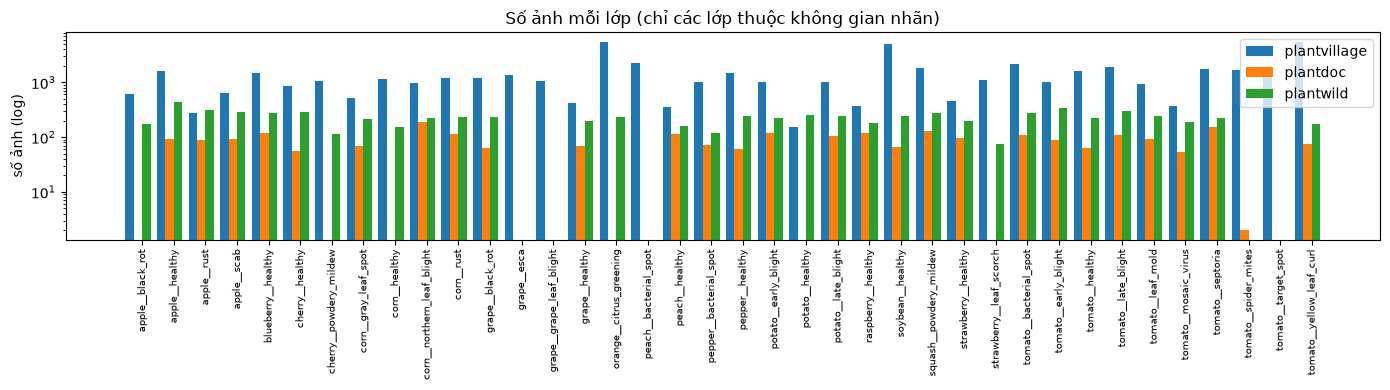

In [11]:
# --- Cell 6.1: phân bố số ảnh theo lớp trong không gian nhãn ---
fig, ax = plt.subplots(figsize=(14, 4))
width = 0.8 / len(data)
for i, (name, d) in enumerate(data.items()):
    cnt = d[d.label >= 0].label.value_counts().reindex(range(len(label_keys)), fill_value=0)
    ax.bar(np.arange(len(label_keys)) + i * width, cnt.values, width, label=name)
ax.set_yscale("log"); ax.set_xticks(np.arange(len(label_keys)) + 0.4)
ax.set_xticklabels(label_keys, rotation=90, fontsize=7); ax.set_ylabel("số ảnh (log)")
ax.legend(); ax.set_title("Số ảnh mỗi lớp (chỉ các lớp thuộc không gian nhãn)")
plt.tight_layout(); plt.savefig(cfg.output_dir / "eda_class_distribution.png", dpi=150); plt.show()

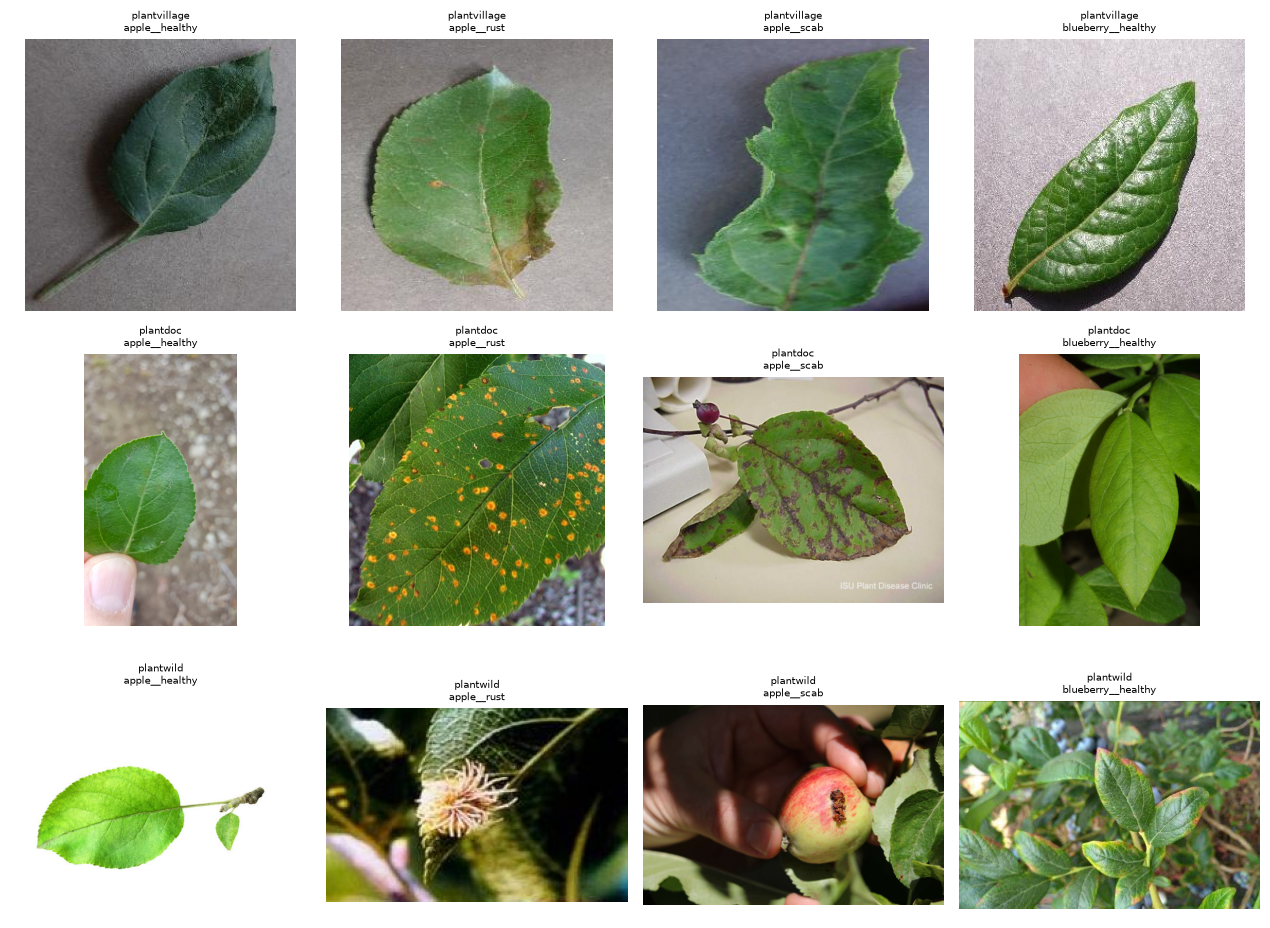

In [12]:
# --- Cell 6.2: ảnh mẫu cùng một lớp ở 3 dataset (so sánh nền, ánh sáng, che khuất) ---
from PIL import Image
common = set.intersection(*[set(d[d.label >= 0].label) for d in data.values()]) if len(data) > 1 else set()
pick = sorted(common)[:4] if common else sorted(pv.label.unique())[:4]
fig, axes = plt.subplots(len(data), len(pick), figsize=(3.2 * len(pick), 3.2 * len(data)), squeeze=False)
for r, (name, d) in enumerate(data.items()):
    for c, lab in enumerate(pick):
        sub = d[d.label == lab]
        ax = axes[r, c]; ax.axis("off")
        if len(sub):
            im = Image.open(sub.sample(1, random_state=0).iloc[0].path); im.draft("RGB", (400, 400))
            ax.imshow(im.convert("RGB"))
        ax.set_title(f"{name}\n{label_keys[lab]}", fontsize=7)
plt.tight_layout(); plt.savefig(cfg.output_dir / "eda_samples.png", dpi=150); plt.show()

## Mục 7. Tập đánh giá và DataLoader
- `PV-test`: kiểm tra **trong miền**.
- `PlantWild-test`: ảnh ngoài đồng, tập test chính thức (không dùng khi fine-tune).
- `PlantDoc`: **độc lập hoàn toàn**. Đánh giá trên toàn bộ ảnh (đã loại ảnh trùng) vì không train trên nó
  (trừ khi `finetune_on="plantdoc"` -> chỉ dùng tập test chính thức).

In [13]:
# --- Cell 7.1: dựng các tập đánh giá ---
pv = data["plantvillage"]
test_sets = {"PV-test": pv[(pv.split == "test") & (pv.label >= 0)]}

if "plantwild" in data:
    pw = data["plantwild"]
    test_sets["PlantWild-test"] = pw[(pw.split == "test") & (pw.label >= 0)]
if "plantdoc" in data:
    pdoc = data["plantdoc"]
    if cfg.finetune_on == "plantdoc" or not cfg.plantdoc_eval_on_all:
        pdoc_eval = pdoc[pdoc.split == "test"]
    else:
        pdoc_eval = pdoc
    pdoc_eval = pdoc_eval[(pdoc_eval.label >= 0) & (~pdoc_eval.path.isin(pdoc_dups))]
    test_sets["PlantDoc"] = pdoc_eval

for k, v in test_sets.items():
    print(f"{k:15s}: {len(v):6d} ảnh, {v.label.nunique():2d} lớp")

PV-test        :   8146 ảnh, 38 lớp
PlantWild-test :   1512 ảnh, 33 lớp
PlantDoc       :   2287 ảnh, 28 lớp


In [14]:
# --- Cell 7.2: transform + loader cho PlantVillage ---
train_tf, eval_tf = build_transforms(cfg.img_size, cfg.augmentation)
pv_train = pv[(pv.split == "train") & (pv.label >= 0)]
pv_val = pv[(pv.split == "val") & (pv.label >= 0)]
pv_train_loader = make_loader(pv_train, train_tf, cfg.batch_size, shuffle=True, num_workers=cfg.num_workers)
pv_val_loader = make_loader(pv_val, eval_tf, cfg.batch_size, shuffle=False, num_workers=cfg.num_workers)
print(f"PV train={len(pv_train)}  val={len(pv_val)}")

PV train=38013  val=8146


## Mục 8. Giai đoạn 1 (S1): huấn luyện trên PlantVillage + đánh giá zero-shot
Mỗi kiến trúc được train trên PlantVillage, rồi đo trên *mọi* tập đánh giá **mà chưa hề thấy ảnh thực tế**.
Kỳ vọng: `PV-test` ~ 99% nhưng `PlantDoc`/`PlantWild-test` thấp hơn rất nhiều -> đó chính là *khoảng cách tổng quát hóa*.
> Lưu ý: PlantVillage có nhiều ảnh cùng một chiếc lá nên `PV-test` có thể bị lạc quan; vì thế cần test xuyên dataset.

In [15]:
# --- Cell 8.1: train từng kiến trúc (có checkpoint -> chạy lại sẽ bỏ qua phần đã train) ---
S1, S2 = "S1: PV-only", "S2: PV->finetune"
RESUME = True
models, histories, tables, R = {}, {}, [], {}     # R[(model, stage, set)] = kết quả chi tiết

def eval_all(model, name, stage):
    rows = [evaluate_set(model, df, eval_tf, cfg, device, sname) for sname, df in test_sets.items()]
    for r in rows: R[(name, stage, r["set"])] = r
    t = results_table(rows, name, stage)
    t["params_M"] = round(count_params(model), 1)
    return t

for name in cfg.models:
    ckpt = cfg.output_dir / f"{name}_s1_pv.pt"
    model = create_model(name, len(label_keys), cfg.pretrained)
    if RESUME and ckpt.exists():
        model.load_state_dict(torch.load(ckpt, map_location=device)); model.to(device)
        print(f"[{name}] nạp checkpoint {ckpt.name}")
    else:
        model, hist = fit(model, pv_train_loader, pv_val_loader, epochs=cfg.epochs_pv, lr=cfg.lr_pv,
                          weight_decay=cfg.weight_decay, label_smoothing=cfg.label_smoothing,
                          amp=cfg.amp, patience=cfg.patience, ckpt_path=ckpt, device=device, tag=name)
        hist.to_csv(cfg.output_dir / f"{name}_s1_history.csv", index=False); histories[name] = hist
    models[name] = model
    tables.append(eval_all(model, name, S1))

s1_table = pd.concat(tables, ignore_index=True)
display(add_generalization_gap(s1_table))

[resnet50] nạp checkpoint resnet50_s1_pv.pt
[efficientnet_b0] nạp checkpoint efficientnet_b0_s1_pv.pt
[mobilenetv3_large_100] nạp checkpoint mobilenetv3_large_100_s1_pv.pt


,model,stage,set,n_images,n_classes,acc,macro_f1,acc_full38,macro_f1_full38,params_M,gap_vs_PV
0,resnet50,S1: PV-only,PV-test,8146,38,0.994108,0.992107,0.994108,0.992107,23.6,0.0000
1,resnet50,S1: PV-only,PlantWild-test,1512,33,0.230820,0.214703,0.220899,0.208445,23.6,0.7633
2,resnet50,S1: PV-only,PlantDoc,2287,28,0.316572,0.259890,0.263664,0.245951,23.6,0.6775
3,efficientnet_b0,S1: PV-only,PV-test,8146,38,0.996563,0.994999,0.996563,0.994999,4.1,0.0000
4,efficientnet_b0,S1: PV-only,PlantWild-test,1512,33,0.221561,0.211032,0.220238,0.211695,4.1,0.7750
5,efficientnet_b0,S1: PV-only,PlantDoc,2287,28,0.271098,0.234689,0.228684,0.224508,4.1,0.7255
6,mobilenetv3_large_100,S1: PV-only,PV-test,8146,38,0.993862,0.991663,0.993862,0.991663,4.3,0.0000
7,mobilenetv3_large_100,S1: PV-only,PlantWild-test,1512,33,0.235450,0.232912,0.231481,0.233002,4.3,0.7584
8,mobilenetv3_large_100,S1: PV-only,PlantDoc,2287,28,0.269786,0.230813,0.235243,0.226319,4.3,0.7241


## Mục 9. Giai đoạn 2 (S2): fine-tune trên ảnh thực tế
Chọn kiến trúc tốt nhất bằng **tập validation ảnh thực tế** (không dùng tập test để chọn mô hình), rồi fine-tune.
Dùng lấy mẫu cân bằng lớp (ảnh thực tế mất cân bằng mạnh) và lr nhỏ hơn, head lr x10.
Đặt `FT_ALL=True` nếu muốn fine-tune mọi kiến trúc (tốn thời gian hơn).

In [16]:
# --- Cell 9.1: dữ liệu fine-tune ---
if cfg.finetune_on == "plantwild" and "plantwild" in data:
    src_df = data["plantwild"]
elif cfg.finetune_on == "plantdoc" and "plantdoc" in data:
    src_df = data["plantdoc"]
else:
    src_df = None
    print("finetune_on='none' hoặc dataset không có -> bỏ qua Giai đoạn 2")

if src_df is not None:
    ft_train = src_df[(src_df.split == "train") & (src_df.label >= 0)]
    ft_val = src_df[(src_df.split == "val") & (src_df.label >= 0)]
    n_real = len(ft_train)
    if cfg.replay_pv_per_class > 0:
        # REPLAY: trộn thêm vài ảnh PlantVillage mỗi lớp để mô hình không "quên" các lớp mà
        # dataset thực tế không có (vd tomato spider mites, grape esca...)
        replay = pv_train.sample(frac=1, random_state=cfg.seed).groupby("label").head(cfg.replay_pv_per_class)
        ft_train = pd.concat([ft_train, replay], ignore_index=True)
        print(f"Replay: +{len(replay)} ảnh PlantVillage ({cfg.replay_pv_per_class}/lớp)")
    ft_train_loader = make_loader(ft_train, train_tf, cfg.batch_size, shuffle=True,
                                  num_workers=cfg.num_workers, balanced=True)
    ft_val_loader = make_loader(ft_val, eval_tf, cfg.batch_size, shuffle=False, num_workers=cfg.num_workers)
    print(f"Fine-tune train={len(ft_train)} (thực tế {n_real})  val={len(ft_val)}  ({ft_train.label.nunique()} lớp)")

Replay: +3800 ảnh PlantVillage (100/lớp)
Fine-tune train=9100 (thực tế 5300)  val=760  (38 lớp)


In [17]:
# --- Cell 9.2: chọn kiến trúc theo val ảnh thực tế (zero-shot) rồi fine-tune ---
FT_ALL = True      # fine-tune cả 3 kiến trúc (~vài phút mỗi mô hình vì tập fine-tune nhỏ)
ft_models, s2_tables = {}, []
if src_df is not None:
    sel = {n: evaluate_set(m, ft_val, eval_tf, cfg, device, "ft-val")["macro_f1"] for n, m in models.items()}
    print("Zero-shot macro-F1 trên val ảnh thực tế:", {k: round(v, 3) for k, v in sel.items()})
    to_ft = list(models) if FT_ALL else [max(sel, key=sel.get)]
    print("Fine-tune:", to_ft)

    for name in to_ft:
        ckpt = cfg.output_dir / f"{name}_s2_ft_replay{cfg.replay_pv_per_class}.pt"   # tên theo cấu hình -> không nạp nhầm checkpoint cũ
        model = create_model(name, len(label_keys), False)
        model.load_state_dict(torch.load(cfg.output_dir / f"{name}_s1_pv.pt", map_location=device))
        if RESUME and ckpt.exists():
            model.load_state_dict(torch.load(ckpt, map_location=device)); model.to(device)
        else:
            model, hist = fit(model, ft_train_loader, ft_val_loader, epochs=cfg.epochs_ft, lr=cfg.lr_ft,
                              head_lr_mult=10.0, weight_decay=cfg.weight_decay,
                              label_smoothing=cfg.label_smoothing, amp=cfg.amp, patience=cfg.patience,
                              ckpt_path=ckpt, device=device, tag=f"{name}-FT")
            hist.to_csv(cfg.output_dir / f"{name}_s2_history.csv", index=False)
        ft_models[name] = model
        s2_tables.append(eval_all(model, name, S2))
    # Chọn kiến trúc tốt nhất theo val ảnh thực tế SAU fine-tune (không dùng tập test để chọn)
    sel2 = {n: evaluate_set(m, ft_val, eval_tf, cfg, device, "ft-val")["macro_f1"] for n, m in ft_models.items()}
    best_name = max(sel2, key=sel2.get)
    print("Val macro-F1 sau fine-tune:", {k: round(v, 3) for k, v in sel2.items()}, "-> best:", best_name)

Zero-shot macro-F1 trên val ảnh thực tế: {'resnet50': 0.199, 'efficientnet_b0': 0.189, 'mobilenetv3_large_100': 0.199}
Fine-tune: ['resnet50', 'efficientnet_b0', 'mobilenetv3_large_100']


[resnet50-FT] ep01 loss=1.9520 tr_acc=0.5852 val_acc=0.3776 val_f1=0.3808 (135s)


[resnet50-FT] ep02 loss=1.5817 tr_acc=0.6821 val_acc=0.5145 val_f1=0.5033 (99s)


[resnet50-FT] ep03 loss=1.4606 tr_acc=0.7246 val_acc=0.5855 val_f1=0.5785 (95s)


[resnet50-FT] ep04 loss=1.3618 tr_acc=0.7588 val_acc=0.5724 val_f1=0.5681 (89s)


[resnet50-FT] ep05 loss=1.3357 tr_acc=0.7671 val_acc=0.6066 val_f1=0.5941 (86s)


... (15 outputs left out)

[mobilenetv3_large_100-FT] ep05 loss=1.2256 tr_acc=0.8065 val_acc=0.6158 val_f1=0.6106 (72s)


[mobilenetv3_large_100-FT] ep06 loss=1.2027 tr_acc=0.8176 val_acc=0.6263 val_f1=0.6251 (72s)


[mobilenetv3_large_100-FT] ep07 loss=1.1774 tr_acc=0.8243 val_acc=0.6355 val_f1=0.6315 (72s)


[mobilenetv3_large_100-FT] ep08 loss=1.1644 tr_acc=0.8320 val_acc=0.6408 val_f1=0.6352 (71s)
Val macro-F1 sau fine-tune: {'resnet50': 0.636, 'efficientnet_b0': 0.666, 'mobilenetv3_large_100': 0.634} -> best: efficientnet_b0


## Mục 10. Kết quả tổng hợp & khoảng cách tổng quát hóa
`gap_vs_PV` = accuracy(PV-test) − accuracy(tập đích): càng nhỏ -> càng tổng quát hóa tốt.

In [18]:
# --- Cell 10.1: bảng kết quả cuối ---
final = add_generalization_gap(pd.concat([s1_table] + s2_tables, ignore_index=True))
final.to_csv(cfg.output_dir / "results_all.csv", index=False)
display(final.drop(columns=[c for c in final.columns if c.startswith("_")]))

pivot = final.pivot_table(index=["model", "stage"], columns="set", values="acc").round(4)
display(pivot)

,model,stage,set,n_images,n_classes,acc,macro_f1,acc_full38,macro_f1_full38,params_M,gap_vs_PV
0,resnet50,S1: PV-only,PV-test,8146,38,0.994108,0.992107,0.994108,0.992107,23.6,0.0000
1,resnet50,S1: PV-only,PlantWild-test,1512,33,0.230820,0.214703,0.220899,0.208445,23.6,0.7633
2,resnet50,S1: PV-only,PlantDoc,2287,28,0.316572,0.259890,0.263664,0.245951,23.6,0.6775
3,efficientnet_b0,S1: PV-only,PV-test,8146,38,0.996563,0.994999,0.996563,0.994999,4.1,0.0000
4,efficientnet_b0,S1: PV-only,PlantWild-test,1512,33,0.221561,0.211032,0.220238,0.211695,4.1,0.7750
5,efficientnet_b0,S1: PV-only,PlantDoc,2287,28,0.271098,0.234689,0.228684,0.224508,4.1,0.7255
6,mobilenetv3_large_100,S1: PV-only,PV-test,8146,38,0.993862,0.991663,0.993862,0.991663,4.3,0.0000
7,mobilenetv3_large_100,S1: PV-only,PlantWild-test,1512,33,0.235450,0.232912,0.231481,0.233002,4.3,0.7584
8,mobilenetv3_large_100,S1: PV-only,PlantDoc,2287,28,0.269786,0.230813,0.235243,0.226319,4.3,0.7241
9,resnet50,S2: PV->finetune,PV-test,8146,38,0.989688,0.986662,0.989688,0.986662,23.6,0.0000


set                                     PV-test  PlantDoc  PlantWild-test
model                 stage                                              
efficientnet_b0       S1: PV-only        0.9966    0.2711          0.2216
                      S2: PV->finetune   0.9937    0.6065          0.6462
mobilenetv3_large_100 S1: PV-only        0.9939    0.2698          0.2354
                      S2: PV->finetune   0.9918    0.6069          0.6210
resnet50              S1: PV-only        0.9941    0.3166          0.2308
                      S2: PV->finetune   0.9897    0.6043          0.6336

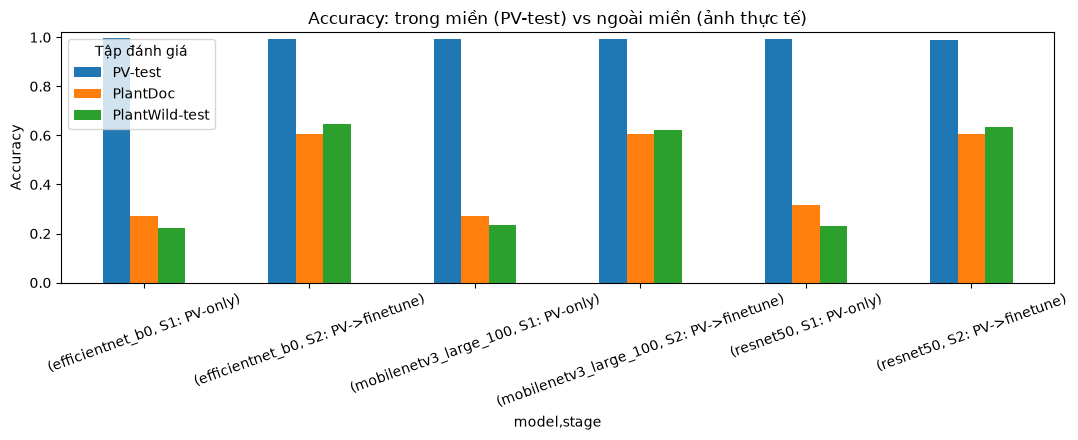

In [19]:
# --- Cell 10.2: biểu đồ accuracy theo tập đánh giá ---
ax = pivot.plot(kind="bar", figsize=(11, 4.5), ylim=(0, 1.02), rot=20)
ax.set_ylabel("Accuracy"); ax.set_title("Accuracy: trong miền (PV-test) vs ngoài miền (ảnh thực tế)")
ax.legend(title="Tập đánh giá"); plt.tight_layout()
plt.savefig(cfg.output_dir / "results_accuracy.png", dpi=150); plt.show()

### 10.3. Nhầm cây hay nhầm bệnh?
`crop_acc` chỉ xét đúng/sai **loại cây**; `disease_acc` xét cả cây lẫn bệnh. Khoảng cách giữa hai cột cho biết
lỗi chủ yếu do nhận sai loại cây (vd khoai tây -> cà chua) hay do nhận sai bệnh trong cùng một loại cây.

In [20]:
# --- Cell 10.3 ---
from src.evaluate import crop_accuracy
rows = [dict(model=m, stage=st, set=s, disease_acc=r["acc"], crop_acc=crop_accuracy(r, label_keys))
        for (m, st, s), r in R.items() if s != "PV-test"]
display(pd.DataFrame(rows).round(4).sort_values(["set", "model", "stage"]))

,model,stage,set,disease_acc,crop_acc
3,efficientnet_b0,S1: PV-only,PlantDoc,0.2711,0.5234
9,efficientnet_b0,S2: PV->finetune,PlantDoc,0.6065,0.8002
5,mobilenetv3_large_100,S1: PV-only,PlantDoc,0.2698,0.5111
11,mobilenetv3_large_100,S2: PV->finetune,PlantDoc,0.6069,0.7875
1,resnet50,S1: PV-only,PlantDoc,0.3166,0.5221
7,resnet50,S2: PV->finetune,PlantDoc,0.6043,0.7967
2,efficientnet_b0,S1: PV-only,PlantWild-test,0.2216,0.3889
8,efficientnet_b0,S2: PV->finetune,PlantWild-test,0.6462,0.7943
4,mobilenetv3_large_100,S1: PV-only,PlantWild-test,0.2354,0.4120
10,mobilenetv3_large_100,S2: PV->finetune,PlantWild-test,0.6210,0.7778


## Mục 11. (Tùy chọn) Ablation: augmentation mạnh có giúp tổng quát hóa?
Train lại kiến trúc tốt nhất ở S1 với augmentation **còn lại** (ngược với `cfg.augmentation`)
và so sánh điểm zero-shot trên ảnh thực tế.

In [21]:
# --- Cell 11.1 ---
RUN_ABLATION = False       # đổi True để chạy (tốn thêm 1 lượt train S1)
if RUN_ABLATION and src_df is not None:
    other = "basic" if cfg.augmentation == "strong" else "strong"
    tr_tf2, _ = build_transforms(cfg.img_size, other)
    ld = make_loader(pv_train, tr_tf2, cfg.batch_size, shuffle=True, num_workers=cfg.num_workers)
    m = create_model(best_name, len(label_keys), cfg.pretrained)
    m, _ = fit(m, ld, pv_val_loader, epochs=cfg.epochs_pv, lr=cfg.lr_pv, amp=cfg.amp,
               patience=cfg.patience, ckpt_path=cfg.output_dir / f"{best_name}_s1_{other}.pt",
               device=device, tag=f"{best_name}-{other}")
    abl = pd.concat([results_table([evaluate_set(m, df, eval_tf, cfg, device, s) for s, df in test_sets.items()],
                                   best_name, f"S1 aug={other}"),
                     results_table([R[(best_name, S1, s)] for s in test_sets], best_name, f"S1 aug={cfg.augmentation}")])
    display(abl)

## Mục 12. Confusion matrix & báo cáo từng lớp
Xem lớp nào bị nhầm khi sang miền ảnh thực tế (thường các bệnh có triệu chứng giống nhau: early/late blight, leaf spot...).

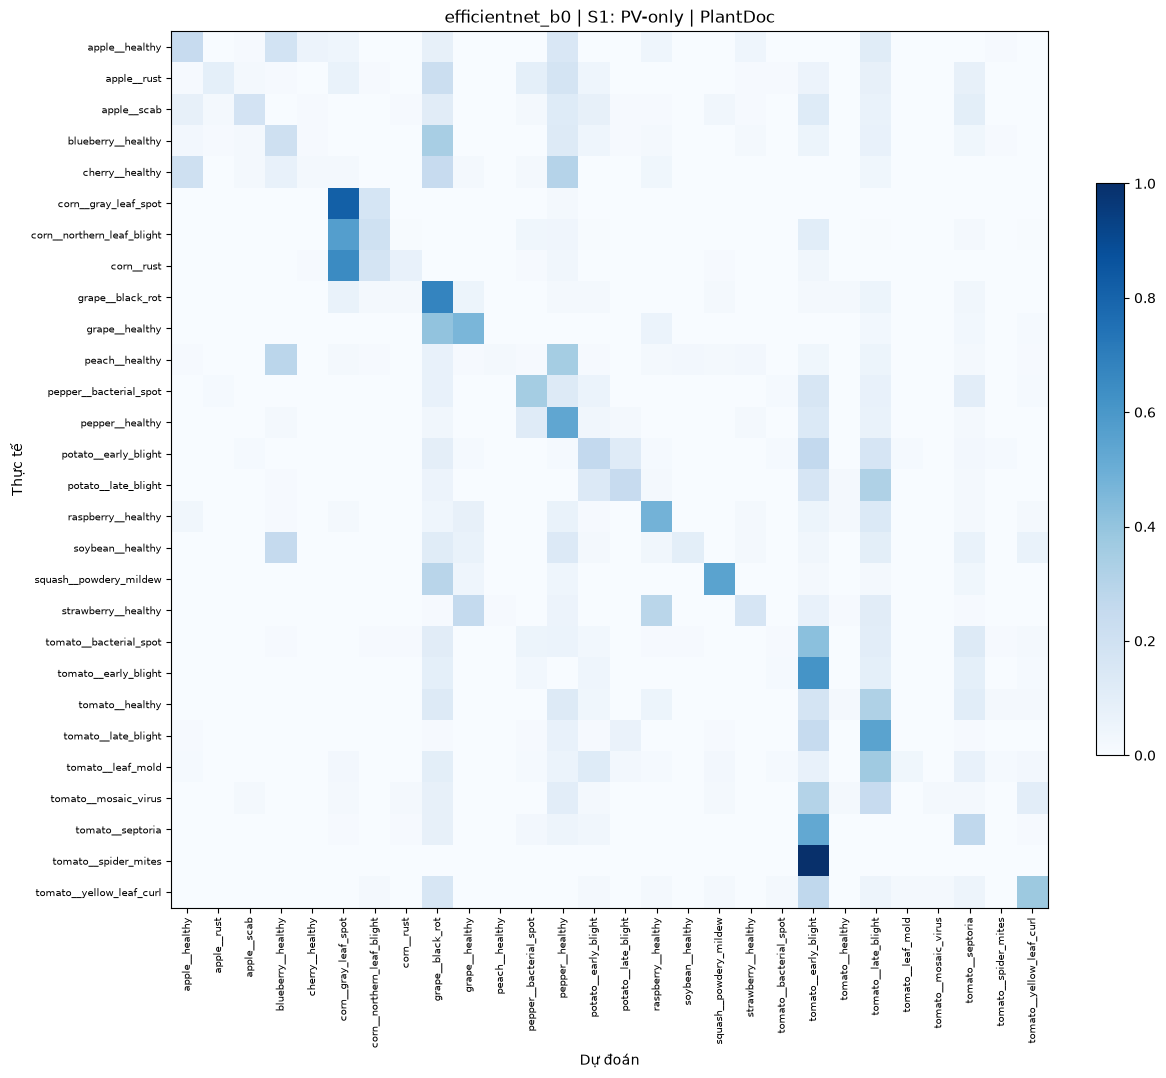

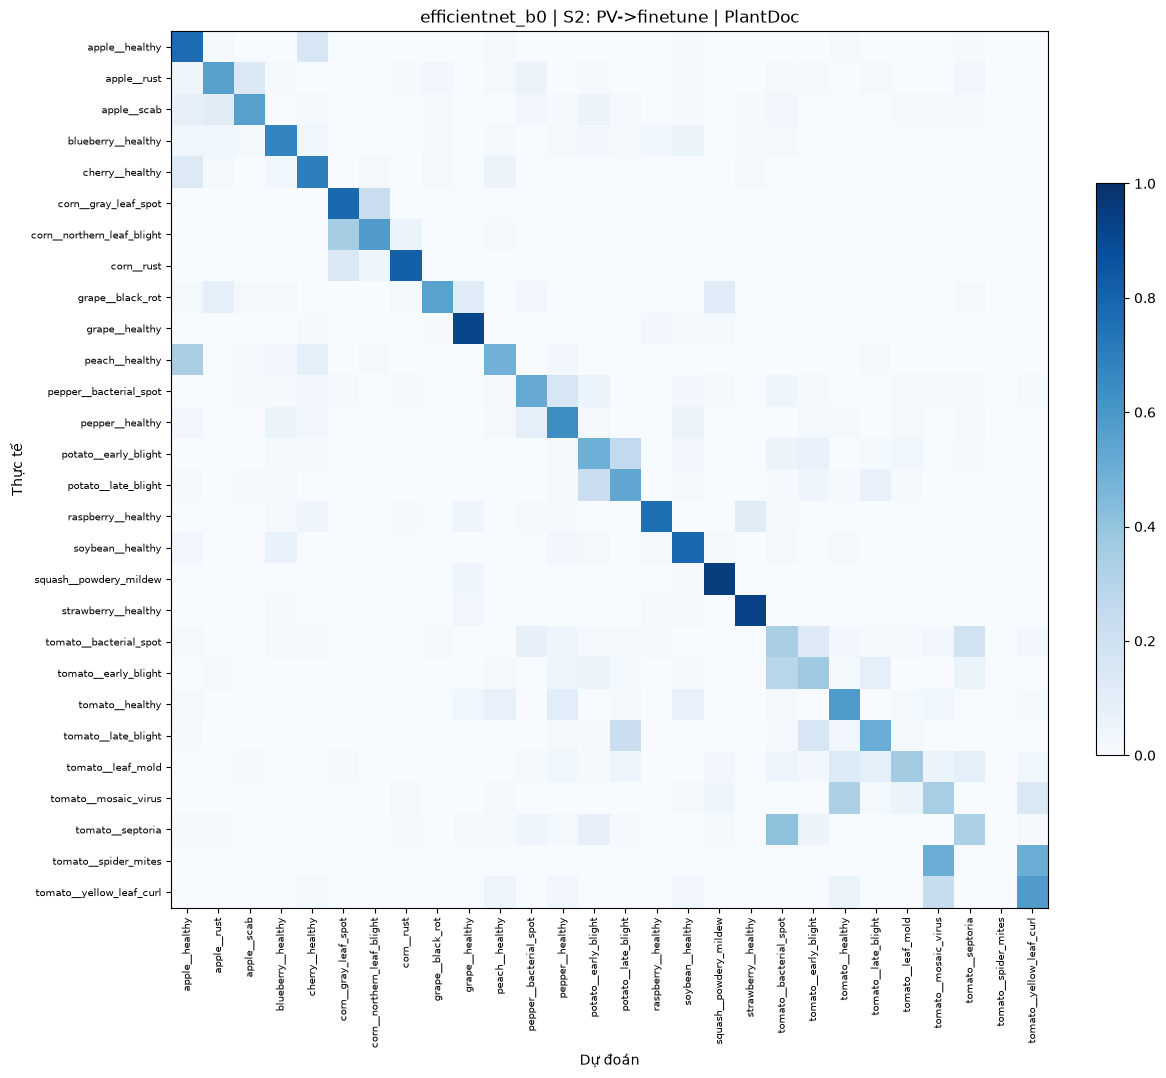

,precision,recall,f1-score,support
apple__healthy,0.485,0.767,0.595,86.000
apple__rust,0.667,0.558,0.608,86.000
apple__scab,0.725,0.562,0.633,89.000
blueberry__healthy,0.781,0.676,0.725,111.000
cherry__healthy,0.462,0.698,0.556,53.000
corn__gray_leaf_spot,0.387,0.780,0.517,59.000
corn__northern_leaf_blight,0.828,0.582,0.683,165.000
corn__rust,0.833,0.815,0.824,92.000
grape__black_rot,0.800,0.552,0.653,58.000
grape__healthy,0.726,0.910,0.808,67.000


In [22]:
# --- Cell 12.1 ---
if src_df is not None:
    target = "PlantDoc" if "PlantDoc" in test_sets else "PlantWild-test"
    for stage in (S1, S2):
        res = R[(best_name, stage, target)]
        plot_confusion(res, label_keys, f"{best_name} | {stage} | {target}",
                       cfg.output_dir / f"cm_{best_name}_{stage[:2]}_{target}.png"); plt.show()
        rep = per_class_report(res, label_keys)
        rep.to_csv(cfg.output_dir / f"perclass_{best_name}_{stage[:2]}_{target}.csv")
    display(per_class_report(R[(best_name, S2, target)], label_keys).round(3))

## Mục 13. Grad-CAM: mô hình nhìn vào đâu?
So sánh S1 (chỉ PlantVillage) và S2 (sau fine-tune) trên cùng ảnh ngoài đồng.
Nếu S1 nhìn vào nền/cạnh lá còn S2 tập trung vào vết bệnh -> bằng chứng định tính cho việc fine-tune giúp tổng quát hóa.

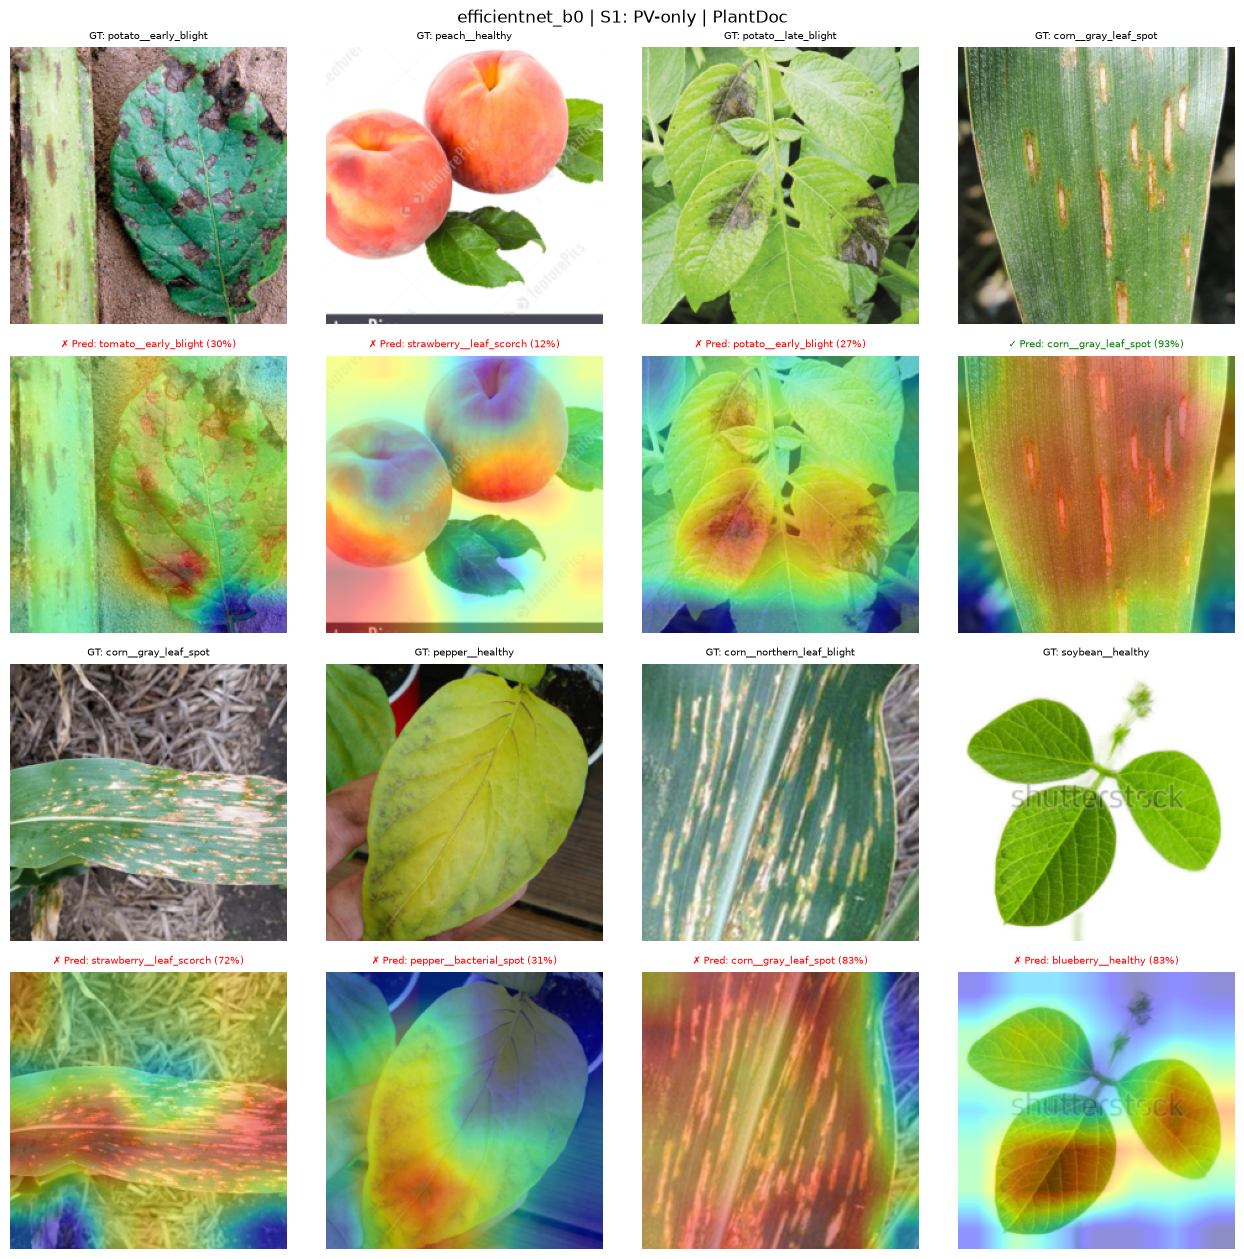

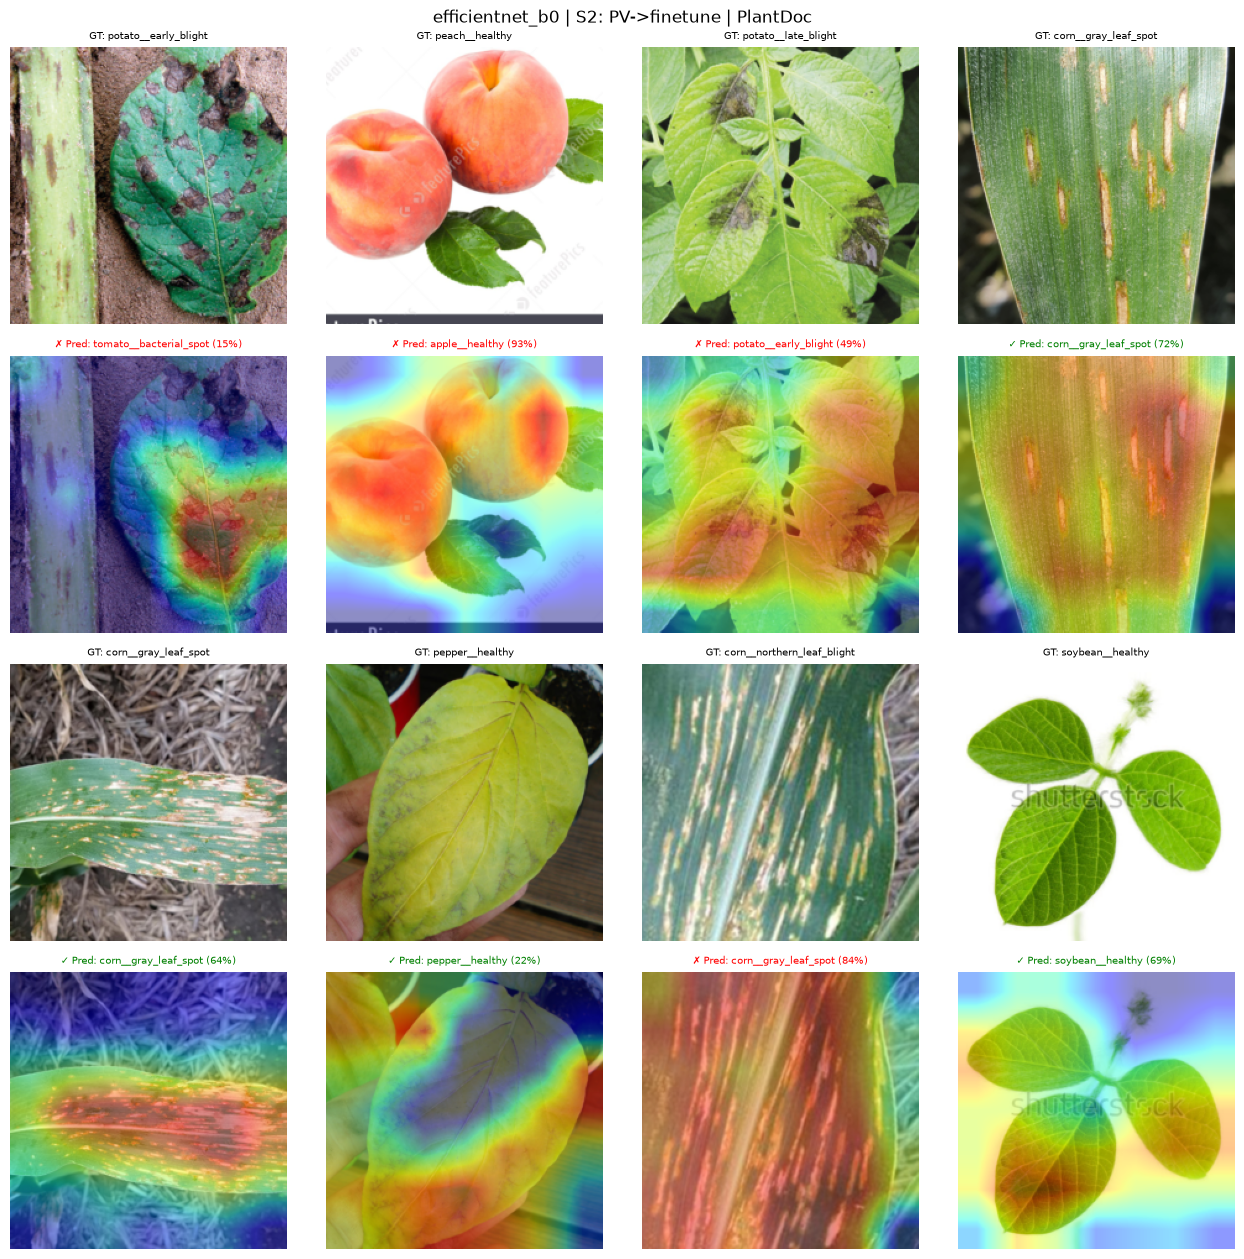

In [23]:
# --- Cell 13.1 ---
if src_df is not None:
    target = "PlantDoc" if "PlantDoc" in test_sets else "PlantWild-test"
    layer_name = best_name
    for stage, mdl in ((S1, models[best_name]), (S2, ft_models[best_name])):
        show_gradcam_grid(mdl, get_gradcam_layer(layer_name, mdl), test_sets[target], eval_tf,
                          label_keys, device, n=8, seed=1, title=f"{best_name} | {stage} | {target}",
                          path=cfg.output_dir / f"gradcam_{stage[:2]}.png"); plt.show()

## Mục 14. Lưu kết quả & kết luận

In [24]:
# --- Cell 14.1 ---
final.to_csv(cfg.output_dir / "results_all.csv", index=False)
print("Đã lưu vào:", cfg.output_dir.resolve())
print(sorted(p.name for p in cfg.output_dir.iterdir()))

# Gợi ý các ý kết luận cho báo cáo (điền số liệu từ bảng Mục 10):
# 1) Độ chính xác trong miền (PV-test) cao nhưng giảm mạnh trên ảnh thực tế -> khoảng cách miền (domain gap).
# 2) Fine-tune với dữ liệu thực tế (PlantWild) cải thiện trên PlantWild-test VÀ trên PlantDoc (chưa từng thấy)
#    -> mô hình học đặc trưng bệnh chứ không chỉ học nền.
# 3) So sánh kiến trúc: độ chính xác / số tham số / tốc độ -> chọn mô hình phù hợp triển khai.
# 4) Hạn chế: ánh xạ nhãn gần đúng; PlantDoc nhỏ; ảnh PV có thể cùng lá giữa train/test; chỉ ~38 lớp chung.

Đã lưu vào: D:\SourceCode\DeepLearning\plant_disease_project_V2\plant_disease_project\outputs
['cm_efficientnet_b0_S1_PlantDoc.png', 'cm_efficientnet_b0_S2_PlantDoc.png', 'cm_mobilenetv3_large_100_S1_PlantDoc.png', 'cm_mobilenetv3_large_100_S2_PlantDoc.png', 'eda_class_distribution.png', 'eda_samples.png', 'efficientnet_b0_s1_history.csv', 'efficientnet_b0_s1_pv.pt', 'efficientnet_b0_s2_ft_replay100.pt', 'efficientnet_b0_s2_history.csv', 'gradcam_S1.png', 'gradcam_S2.png', 'mobilenetv3_large_100_s1_history.csv', 'mobilenetv3_large_100_s1_pv.pt', 'mobilenetv3_large_100_s2_ft.pt', 'mobilenetv3_large_100_s2_ft_replay100.pt', 'mobilenetv3_large_100_s2_history.csv', 'perclass_efficientnet_b0_S1_PlantDoc.csv', 'perclass_efficientnet_b0_S2_PlantDoc.csv', 'perclass_mobilenetv3_large_100_S1_PlantDoc.csv', 'perclass_mobilenetv3_large_100_S2_PlantDoc.csv', 'plantdoc_plantwild_duplicates.csv', 'resnet50_s1_history.csv', 'resnet50_s1_pv.pt', 'resnet50_s2_ft_replay100.pt', 'resnet50_s2_history.csv',